# MnTe using Altermagnetic Symmetry

Altermagnets (as well as antiferromagnets) have a nice property, that, unlike Ferromagnets, their spin-up and spin-down channels are related by a symmetry operation. This symmetry may be a rotation (altermagnetic symmetry) or a translation or space inversion (antiferromagnetic symmetry). Therefore, it is not needed to separately wannierise the spin-down channel, it is enough to wannierise the spin-up and apply the symmetry. This tutorial demonstrates ho to do it.

Comppare with the [previous tutorial](https://tutorial.wannier-berri.org/tutorials/8_GPAW/3.MnTe/mnte.html) , where the spin-up and spin-down channels were wannierised separately. 

In [1]:
from sys import stdout

import numpy as np
from ase import Atoms
from gpaw import GPAW, PW, MixerSum
import ray
ray.init(num_cpus=16)

seed = "MnTe"


/home/stepan/storage/github/WannierBerri-tutorial/.conda/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-16 12:31:04,329	INFO util.py:154 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.
2026-10-16 12:31:11,720	INFO worker.py:2004 -- Started a local Ray instance. View the dashboard at http://127.0.0.1:8266 
/home/stepan/storage/github/WannierBerri-tutorial/.conda/lib/python3.12/site-packages/ray/_private/worker.py:2052: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message, set RAY_ACCEL_ENV_VAR_OVERRIDE_ON_ZERO=0
  warnings.warn(


## Configure Logging

The new version of WannierBerri has a configurable logging system. See documentation for details. Were we just want to see the output in the notebook, so we modify the console_level

In [2]:

from wannierberri.logging import configure_logging
configure_logging(console_level="INFO")

<Logger wannierberri (INFO)>


## Step 1: Gpaw calculation

THe gpaw calculation is the same as in the previous tutorial, so we skip them here, just loading the results.


In [3]:
calc_scf = GPAW(f"gpaw/{seed}-scf.gpw")
calc_nscf = GPAW(f"gpaw/{seed}-nscf-irred-664.gpw")
calc_bands = GPAW(f"gpaw/{seed}-bands-path.gpw")

## Step 2: Wannierization

#### 2.1 select projections

In this case we use sp3d2 and t2g projections on each iron atom.  One can also use the conventional s,p,d orbitals. 

In [4]:
from irrep.spacegroup import SpaceGroup
from wannierberri.symmetry.projections import Projection, ProjectionsSet

sg = SpaceGroup.from_gpaw(calc_nscf, include_TR=True)

at_numbers = calc_nscf.atoms.get_atomic_numbers()
at_positions = calc_nscf.atoms.get_scaled_positions()
at_magmom = calc_nscf.get_magnetic_moments()

print (f"Atomic numbers: {at_numbers}")
print (f"Atomic positions: \n {at_positions}")
print (f"Atomic magnetic moments: {at_magmom}")

positions_Mn_up = at_positions[(at_numbers == 25) & (at_magmom > 0)]  # Mn atoms with positive magnetic moment
positions_Mn_down = at_positions[(at_numbers == 25) & (at_magmom < 0)]  # Mn atoms with negative magnetic moment
positions_Te = at_positions[at_numbers == 52]  # Te atoms

print (f"Positions of Mn atoms with positive magnetic moment: {positions_Mn_up}")
print (f"Positions of Mn atoms with negative magnetic moment: {positions_Mn_down}")
print (f"Positions of Te atoms: \n{positions_Te}")

proj_Mn_up_d = Projection(position_num=positions_Mn_up, orbital='d', spacegroup=sg)
proj_Te_sp2 = Projection(position_num=positions_Te, orbital='sp2', spacegroup=sg, xaxis=[0, -1, 0], rotate_basis=True)
proj_Te_pz = Projection(position_num=positions_Te, orbital='pz', spacegroup=sg)

proj_set_up = ProjectionsSet([proj_Mn_up_d, proj_Te_sp2, proj_Te_pz])



Atomic numbers: [25 25 52 52]
Atomic positions: 
 [[0.         0.         0.        ]
 [0.         0.         0.5       ]
 [0.33333333 0.66666667 0.25      ]
 [0.66666667 0.33333333 0.75      ]]
Atomic magnetic moments: [ 4.40436811e+00 -4.40436811e+00 -2.92436707e-10 -2.92437089e-10]
Positions of Mn atoms with positive magnetic moment: [[0. 0. 0.]]
Positions of Mn atoms with negative magnetic moment: [[0.  0.  0.5]]
Positions of Te atoms: 
[[0.33333333 0.66666667 0.25      ]
 [0.66666667 0.33333333 0.75      ]]


### create the "w90 files"

Here we are NOT using the gpaw-wannier90 interface, and actually not creating the w90 files, but directly access the wavefunctions from the GPAW calculation, use symmetry operations from irrep, and create the necessary data to be used with wannierberri. Those files still retain the same naming convention as the w90 files for consistency, but htey are binary npz files, which are convenient to work with numpy


After creating those data, it is written to the disk, so that one can later load it. But be careful - if you change anything (e.g. the projections)  - do not forget to remove those files, otherwise you will load the old data! For that reason, here we set 'read_npz_list=[]' to force the creation of new data.

In [5]:
from wannierberri.w90files.w90data_soc import WannierDataSOC
wandata = WannierDataSOC.from_gpaw(
    seedname="wannier_soc_altermagnetic",
    calculator=calc_nscf,
    projections_up=proj_set_up,
    mp_grid=(6, 6, 4),
    altermagnetic=True,
)
wandata.to_npz("wannier_soc_altermagnetic")

2026-10-16 12:31:26,657 INFO wannierberri.symmetry.projections: finding num points from 3 projections
2026-10-16 12:31:26,668 INFO wannierberri.symmetry.projections: finding num points from 3 projections
mpgrid = [6 6 4], 24
2026-10-16 12:31:26,675 WARNING wannierberri.w90files.wandata: detected grid (np.int64(6), np.int64(6), np.int64(4)) od 144 kpoints, but only 24 kpoints are available.assuming that only irreducible kpoints are needed.
mpgrid = [6 6 4], 24
2026-10-16 12:31:37,944 INFO wannierberri.w90files.amn: Creating amn. Using projections_set 
ProjectionsSet with 13 Wannier functions and 0 free variables
Projection 0.0, 0.0, 0.0:['d'] with 5 Wannier functions (5 per spin x1 spins) 
 on 1 points (5 per site)
Projection 0.3333333333333334, 0.6666666666666667, 0.25:['sp2'] with 6 Wannier functions (6 per spin x1 spins) 
 on 2 points (3 per site)
Projection 0.3333333333333334, 0.6666666666666667, 0.25:['pz'] with 2 Wannier functions (2 per spin x1 spins) 
 on 2 points (1 per site)
2

### Do the wannierization

at this step we also specify the frozen window, number of iterations, and whether to use site 
symmetry and localization. (when starting from irreducible BZ, site-symmetry is required anyway)

We also may use the outer window via w90data.select_bands if needed

In this case,  only the spin-up channel is wannierised (compare with the previous tutorial)

In [6]:
wandata.wannierise(
    froz_min=-10,
    froz_max=7,
    outer_min=-10,
    outer_max=np.inf,
    num_iter=200,
    print_progress_every=50,
    sitesym=True,
    localise=True,
)



2026-10-16 12:32:26,859 WARNING wannierberri.wannierisation.wannierise: The check of irreps is not implemented for anti-unitary symmetries. Skipping the check, leaving to your responsibility
2026-10-16 12:32:26,859 INFO wannierberri.wannierisation.wannierise: Using the Wannier centers from the projections as initial guess
2026-10-16 12:32:26,892 WARNING wannierberri.symmetry.sawf_kirr: symmetrization did not converge in 10 iterations, final changes 0.005566396361527378, 5.182668731547316e-05; probably the input data are not perfectly symmetrizable, or the provided projections are notcompatible with the irreps of the DFT bands.
2026-10-16 12:32:26,950 WARNING wannierberri.symmetry.sawf_kirr: symmetrization did not converge in 10 iterations, final changes 0.005165982698516518, 3.487585752635262e-05; probably the input data are not perfectly symmetrizable, or the provided projections are notcompatible with the irreps of the DFT bands.
2026-10-16 12:32:26,956 WARNING wannierberri.symmetry.

### Create the System object to be used in WannierBerri calculations

It is called "System_w90" class, although it now does not use the w90 wannierization, but the class is the same.

Unlike the non-SOC systems, here we also specify the direction of the magnetization. We can later easily chanbge this direction without redoing the wannierization.

In [12]:
from wannierberri.system.system_soc import SystemSOC
theta = 90
phi = 90

system_soc_altermagnetic = SystemSOC.from_wannierdata(wandata=wandata, berry=True, silent=False)
system_soc_altermagnetic.set_soc_axis(theta=theta, phi=phi, alpha_soc=1.0, units="degrees")
system_soc_altermagnetic.save_npz("system_soc_altermagnetic")


2026-10-16 12:36:42,638 INFO wannierberri.system.system_w90: irreducible : True, symmetrize set to True
2026-10-16 12:36:42,882 INFO wannierberri.symmetry.sym_wann_2: num_blocks_left = 3, num_blocks_right = 3
2026-10-16 12:36:42,882 INFO wannierberri.system.system_R: number o R-vectors before symmetrization: 267
2026-10-16 12:36:47,235 INFO wannierberri.system.system_R: number o R-vectors after symmetrization: 573

 ### 1 

rotation : |  1   0   0 |
           |  0   1   0 |
           |  0   0   1 |


 gk = [kx, ky, kz]

translation         :  [   0.0000   0.0000   0.0000 ] 

axis: [0. 0. 1.] ; angle =  0 , inversion: False, time reversal: False

 ### -1 

rotation : |  1   0   0 |
           |  0   1   0 |
           |  0   0   1 |


 gk = [kx, ky, kz]

translation         :  [   0.0000   0.0000   0.0000 ] 

axis: [0. 0. 1.] ; angle =  0 , inversion: False, time reversal: False

 ### 2 

rotation : |  1   0   0 |
           |  0   1   0 |
           |  0   0   1 |


 gk = [-kx, -ky, 

### Compute the wannierized bandstructure with SOC along the high-symmetry path

In [16]:
from wannierberri.grid import Path
from wannierberri.evaluate_k import evaluate_k_path
from wannierberri.system.system_soc import SystemSOC
system_soc_altermagnetic = SystemSOC.from_npz("system_soc_altermagnetic")
system_soc_altermagnetic.set_soc_axis(theta=theta, phi=phi, alpha_soc=1.0, units="degrees")
# load the system from the previous tutorial for comparison
system_soc = SystemSOC.from_npz("system_soc")
system_soc.set_soc_axis(theta=theta, phi=phi, alpha_soc=1.0, units="degrees")



lattice = system_soc.real_lattice
c = lattice[2, 2]
kz = 0.35 / (2*np.pi/c)
path = Path.from_nodes(real_lattice=lattice,
            nodes=[
                [2 / 3, -1 / 3, 0],
                [0, 0, 0],
                [-2 / 3, 1 / 3, 0],
                None,
                [-0.5, 0, kz],
                [0, 0, kz],
                [0.5, 0, kz],
            ],
            labels=[r"${\rm K}\leftarrow$",
                    r"$\Gamma$",
                    r"$\rightarrow{\rm K}$",
                    r"$\overline{\rm M}\leftarrow$",
                    r"$\overline{\Gamma}$",
                    r"$\rightarrow\overline{\rm M}$"],
            length=300)   # length [ Ang] ~= 2*pi/dk

bands_wannier_soc= evaluate_k_path(system_soc, path=path, quantities=["spin"])
bands_wannier_up = evaluate_k_path(system_soc.system_up, path=path)
bands_wannier_dw = evaluate_k_path(system_soc.system_down, path=path)

bands_wannier_altermagnetic_soc= evaluate_k_path(system_soc_altermagnetic, path=path, quantities=["spin"])
bands_wannier_altermagnetic_up = evaluate_k_path(system_soc_altermagnetic.system_up, path=path)
bands_wannier_altermagnetic_dw = evaluate_k_path(system_soc_altermagnetic.system_down, path=path)


loading real_lattice
  - Ok!
loading wannier_centers_cart
  - Ok!
loading iRvec
  - Ok!
loading is_phonon
  - Ok!
loading num_wann
  - Ok!
loading periodic
  - Ok!
loading positions
  - Ok!
loading pointgroup
  - Ok!
loading atom_labels
  - Ok!
loading R_matrix dV_socloading dV_soc - Ok!
loading R_matrix AAloading AA - Ok!
loading R_matrix Hamloading Ham - Ok!
loading real_lattice
  - Ok!
loading wannier_centers_cart
  - Ok!
loading iRvec
  - Ok!
loading is_phonon
  - Ok!
loading num_wann
  - Ok!
loading periodic
  - Ok!
loading positions
  - Ok!
loading pointgroup
  - Ok!
loading atom_labels
  - Ok!
loading R_matrix dV_socloading dV_soc - Ok!
loading R_matrix AAloading AA - Ok!
loading R_matrix Hamloading Ham - Ok!
2026-10-16 12:38:12,697 INFO wannierberri.system.system_soc: using magmoms 
 [[ 2.69689765e-16  4.40436811e+00  2.69689765e-16]
 [-2.69689765e-16 -4.40436811e+00 -2.69689765e-16]
 [-1.79065955e-26 -2.92436898e-10 -1.79065955e-26]
 [-1.79065955e-26 -2.92436898e-10 -1.7906595

## Plot the Bandstructure with and without SOC

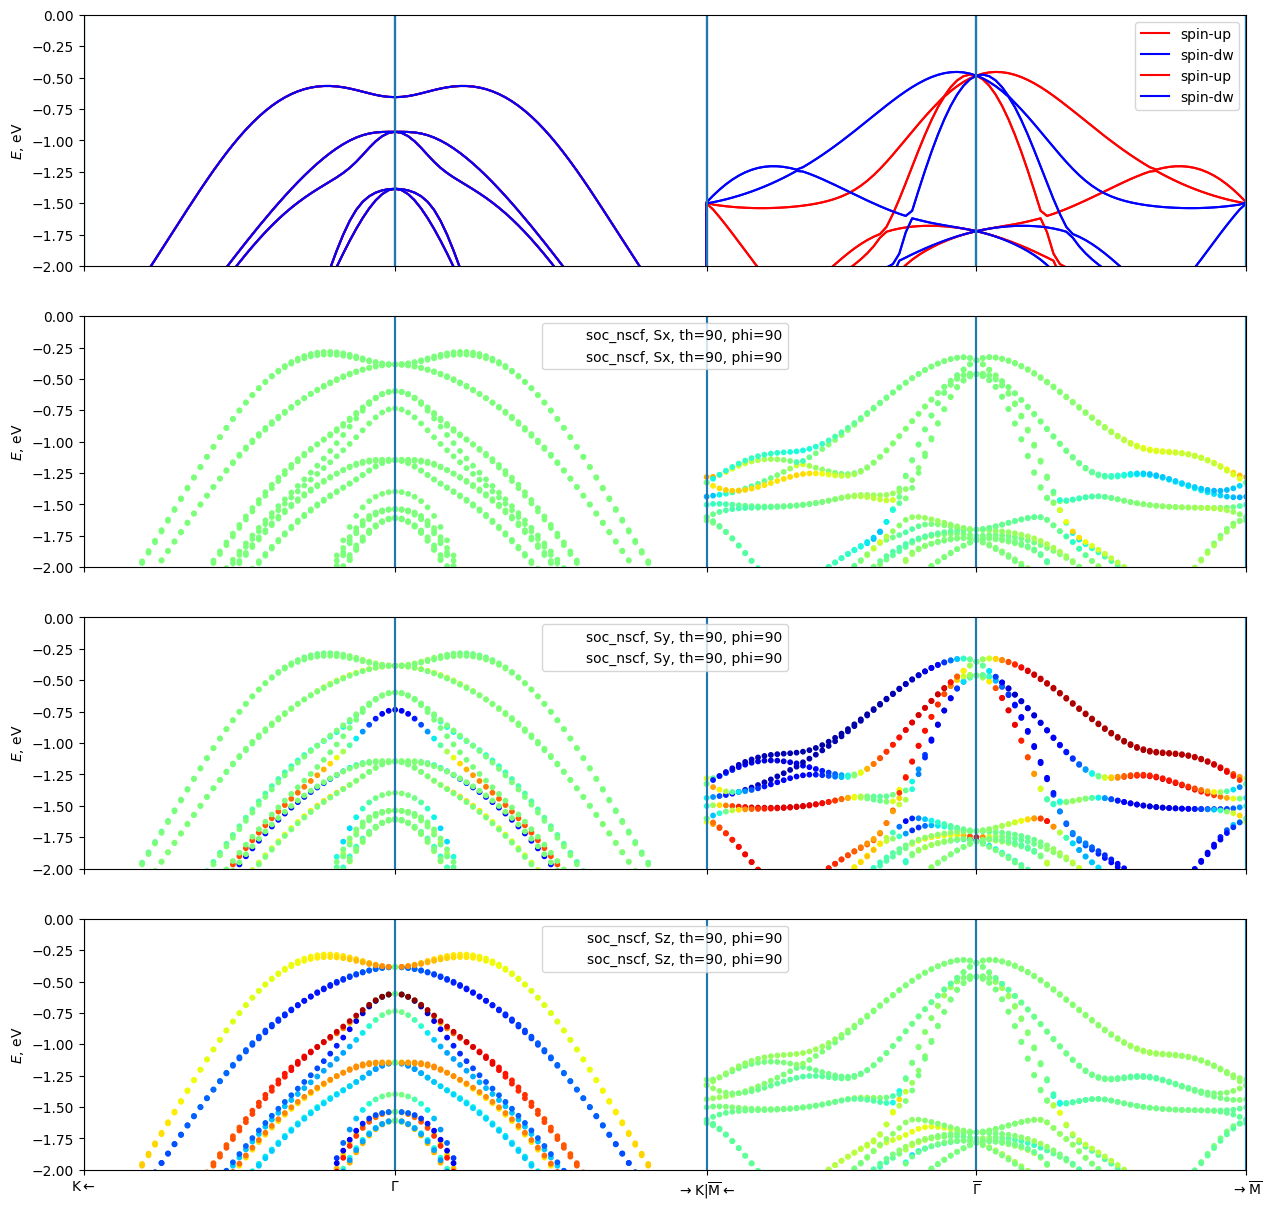

In [ ]:
from matplotlib import pyplot as plt

EF = 6.885145845031927

fig, axes = plt.subplots(6, 1, sharey=True, sharex=True, figsize=(15, 15))

for linestyle, (bands_soc, bands_up, bands_down) in [
    ('-', (bands_wannier_soc, bands_wannier_up, bands_wannier_dw)),
    (':', (bands_wannier_altermagnetic_soc, bands_wannier_altermagnetic_up, bands_wannier_altermagnetic_dw))     
]:

    for i in range(3):
        component = "xyz"[i]
        bands_soc.plot_path_fat(path=path,
                        Eshift=EF,
                        quantity="spin",
                        component=component,
                        mode="color",
                        label=f"soc_nscf, S{component}, th={theta}, phi={phi}",
                            axes=axes[1 + i],
                        fatmax=10,
                            linecolor="orange",
                            close_fig=False,
                            show_fig=False,
                            kwargs_line=dict(linestyle=linestyle, lw=0.0),
        )


    bands_up.plot_path_fat(path=path,
                        Eshift=EF,
                        axes=axes[0],
                        label="spin-up",
                        linecolor="red",
                        close_fig=False,
                        show_fig=False,
    )

    bands_down.plot_path_fat(path=path,
                        label="spin-dw",
                        axes=axes[0],
                        Eshift=EF,
                        linecolor="blue",
                        close_fig=False,
                            show_fig=False,)

plt.ylim(-2,0)
plt.show()


## AHC

### magnetic moments along "y" direction

Below we evaluate only the "internal" (which depend only on the Hamiltonian) contributions to the anomalous Hall conductivity (AHC), how to include the "external" contributions is explained in the previous tutorial on bcc Fe.

In [ ]:
import os
import numpy as np
import wannierberri as wb
from wannierberri.system.system_soc import SystemSOC


system_soc_y = SystemSOC.from_npz("system_soc")
theta=90
phi=90
system_soc_y.set_soc_axis(theta=theta, phi=phi, units="degrees")

grid = wb.grid.Grid(system_soc_y, NK=200)

EF = 6.885145845031927
tetra = False

Efermi = np.linspace(EF - 2, EF, 1001)

os.makedirs("results", exist_ok=True)
result_int = wb.run(system_soc_y,
        grid=grid,
        fout_name=f"results/{seed}-soc-y",
        calculators={"ahc_int": wb.calculators.static.AHC(Efermi=Efermi, tetra=tetra, kwargs_formula={"external_terms": False})},
        adpt_num_iter=20,
        )


### plot AHC vs energy

In [ ]:
from matplotlib import pyplot as plt
import numpy as np
theta=0
phi=0


fig, axes = plt.subplots(1, 1, sharey=False, sharex=True, figsize=(10, 8))
axes=[axes]
imin = 0
imax = 20
for i in range(imin, imax+1, 1):
    t = (i-imin)/(imax-imin)
    res =  np.load(f"results/MnTe-soc-y-ahc_int_iter-{i:04d}.npz")
    Efermi = res['Energies_0']
    ahc = res["data"]
    axes[0].plot(Efermi - EF, ahc[:,2]/100, label=f"iter={i}", color=(0, 1-t, t))
axes[0].set_title("AHC internal terms convergence")
# axes[0].set_ylim(-1000, 0)
axes[0].set_xlabel("E-EF (eV)")
axes[0].set_ylabel("AHC (S/cm)")
axes[0].legend()
plt.tight_layout()
plt.savefig("ahc_convergence.png", dpi=300)

We can observe 3 things, which are generally true, not only for AHC, but for most other effects:
1. The internal terms converge slower than the external ones.
2. The external terms usually give a smaller contribution. Often (but not always) it is negligible. However, check it for a particular material and effect.
3. The external terms take more time to evaluate per k-point. 

Thus, it makes sense to evaluate them separately, using different k-point grids and number of iterations for the adaptive integration.

## Other directions of magnetic moments

We could try to calculate the AHC when the magnetic moments are along "z" or "x" directions. However, we can see that in those cases the point group contains symmetries which force the AHC to be zero. 
This can be demonstrated by the following way:

In [ ]:
from irrep.spacegroup import SpaceGroup
from wannierberri.symmetry.point_symmetry import PointGroup

#  x direction
mg = SpaceGroup.from_cell(real_lattice=lattice, positions=positions, typat=[1,1,2,2], magmom=[[1,0,0],[-1,0,0],[0,0,0],[0,0,0]])
# mg.show()
pointgroup = PointGroup(spacegroup=mg)
print (f"components of AHC for magnetic moments along x direction: {pointgroup.get_symmetric_components(rank=1, TRodd=True, Iodd=False)}")

mg = SpaceGroup.from_cell(real_lattice=lattice, positions=positions, typat=[1,1,2,2], magmom=[[0,1,0],[0,-1,0],[0,0,0],[0,0,0]])
# mg.show()
pointgroup = PointGroup(spacegroup=mg)
print (f"components of AHC for magnetic moments along y direction: {pointgroup.get_symmetric_components(rank=1, TRodd=True, Iodd=False)}")

mg = SpaceGroup.from_cell(real_lattice=lattice, positions=positions, typat=[1,1,2,2], magmom=[[0,0,1],[0,0,-1],[0,0,0],[0,0,0]])
# mg.show()
pointgroup = PointGroup(spacegroup=mg)
print (f"components of AHC for magnetic moments along z direction: {pointgroup.get_symmetric_components(rank=1, TRodd=True, Iodd=False)}")